# Модель Изинга на энергосетях

Спин узла: `+1` — подстанция работает, `-1` — отказала. Энергия `H = -J Σ s_i s_j`, динамика — алгоритм Метрополиса, `T` — уровень межсистемного хаоса.

In [32]:
import os, time
import numpy as np
import networkx as nx
import matplotlib.pyplot as plt

try:
    from numba import njit
    HAS_NUMBA = True
except ImportError:
    HAS_NUMBA = False
    print("numba не найдена: расчёт будет в десятки раз медленнее. Лучше: pip install numba")

    def njit(*args, **kwargs):
        if len(args) == 1 and callable(args[0]) and not kwargs:
            return args[0]
        return lambda f: f

plt.rcParams.update({
    "figure.dpi": 100,
    "font.size": 10,
    "axes.titlesize": 13,
    "axes.titleweight": "bold",
})

# ---------------- НАСТРОЙКИ ----------------
J = 1.0
T_MIN, T_MAX, N_TEMPS = 0.4, 4.5, 60          # диапазон температур
SIM = dict(n_thermal=2000, n_measure=3000,     # разогрев / измерения (в проходах по сети)
           n_runs=5, seed=42)                  # число независимых запусков для усреднения

DATA_DIR = "../data"                              # папка с вашими файлами графов
# Явный список файлов {"Название сети": "путь"}. Пусто {} = взять ВСЕ графы из DATA_DIR.
# Пример: GRAPH_FILES = {"Моя сеть": r"C:\data\net.graphml", "Вторая": "data/other.csv"}
GRAPH_FILES = {}
USE_WEIGHTS = False                            # True: брать вес ребра (атрибут "weight" / 3-й столбец)
LARGEST_COMPONENT = True                       # работать только с наибольшей связной компонентой
RUN_LATTICE_CHECK = True                       # проверка ядра на решётке 2D (T_c ≈ 2.27)

## 1. Физическое ядро (Метрополис)

In [33]:
@njit
def seed_numba(seed):
    np.random.seed(seed)


@njit
def calculate_energy(spins, indptr, indices, weights, J):
    E = 0.0
    for i in range(spins.shape[0]):
        s = 0.0
        for k in range(indptr[i], indptr[i + 1]):
            s += weights[k] * spins[indices[k]]
        E -= J * spins[i] * s
    return E / 2.0          # каждое ребро учтено дважды


@njit
def metropolis_sweep(spins, indptr, indices, weights, J, T):
    N = spins.shape[0]
    for _ in range(N):
        i = np.random.randint(0, N)
        s = 0.0
        for k in range(indptr[i], indptr[i + 1]):
            s += weights[k] * spins[indices[k]]
        dE = 2.0 * J * spins[i] * s
        if dE <= 0.0 or np.random.random() < np.exp(-dE / T):
            spins[i] = -spins[i]


@njit
def relax(spins, indptr, indices, weights, J, T, n_sweeps):
    for _ in range(n_sweeps):
        metropolis_sweep(spins, indptr, indices, weights, J, T)


@njit
def run_temperature(spins, indptr, indices, weights, J, T, n_thermal, n_measure):
    """Разогрев + измерения при одной T. Возвращает <E>, <E^2>, <|m|>, <m^2>."""
    N = spins.shape[0]
    relax(spins, indptr, indices, weights, J, T, n_thermal)
    sE = 0.0
    sE2 = 0.0
    sM = 0.0
    sM2 = 0.0
    for _ in range(n_measure):
        metropolis_sweep(spins, indptr, indices, weights, J, T)
        E = calculate_energy(spins, indptr, indices, weights, J)
        m = 0.0
        for i in range(N):
            m += spins[i]
        m /= N
        sE += E
        sE2 += E * E
        sM += abs(m)
        sM2 += m * m
    return sE / n_measure, sE2 / n_measure, sM / n_measure, sM2 / n_measure

## 2. Загрузка графов и топология

In [34]:
class Network:
    """CSR-массив"""

    def __init__(self, name, G, use_largest=True, use_weights=False, weight_key="weight"):
        G = nx.Graph(G)                                   # простой неориентированный граф
        G.remove_edges_from(list(nx.selfloop_edges(G)))
        self.n_components_raw = nx.number_connected_components(G)
        self.n_nodes_raw = G.number_of_nodes()
        if use_largest and self.n_components_raw > 1:
            G = G.subgraph(max(nx.connected_components(G), key=len)).copy()
        self.name = name
        self.graph = G
        self.nodes = list(G.nodes())
        idx = {v: i for i, v in enumerate(self.nodes)}
        indptr, indices, weights = [0], [], []
        for v in self.nodes:
            for u, d in G[v].items():
                indices.append(idx[u])
                w = 1.0
                if use_weights:
                    try:
                        w = abs(float(d.get(weight_key, 1.0)))
                    except (TypeError, ValueError):
                        w = 1.0
                weights.append(w)
            indptr.append(len(indices))
        self.indptr = np.array(indptr, dtype=np.int64)
        self.indices = np.array(indices, dtype=np.int64)
        self.weights = np.array(weights, dtype=np.float64)

    @property
    def N(self):
        return len(self.nodes)

    def random_spins(self, rng):
        return rng.choice(np.array([1, -1], dtype=np.int64), size=self.N)


GRAPH_EXTS = (".graphml", ".gml", ".gexf", ".edgelist", ".edges", ".txt", ".csv", ".tsv")
_HEADER_WORDS = {"source", "target", "from", "to", "u", "v", "src", "dst", "node1", "node2", "id1", "id2"}


def read_edge_list(path):
    """Список рёбер: строка = 'u v [вес]', разделитель - запятая, ;, таб или пробел."""
    import re
    G = nx.Graph()
    with open(path, encoding="utf-8-sig") as f:
        for n, line in enumerate(f):
            line = line.strip()
            if not line or line.startswith(("#", "%", "//")):
                continue
            parts = [p for p in re.split(r"[,;\t ]+", line) if p]
            if len(parts) < 2:
                continue
            if n == 0 and parts[0].lower() in _HEADER_WORDS:
                continue
            attrs = {}
            if len(parts) >= 3:
                try:
                    attrs["weight"] = float(parts[2].replace(",", "."))
                except ValueError:
                    pass
            G.add_edge(parts[0], parts[1], **attrs)
    return G


def read_graph_file(path):
    ext = os.path.splitext(path)[1].lower()
    if ext == ".graphml":
        return nx.read_graphml(path)
    if ext == ".gml":
        try:
            return nx.read_gml(path)
        except Exception:
            return nx.read_gml(path, label="id")
    if ext == ".gexf":
        return nx.read_gexf(path)
    return read_edge_list(path)


def discover_graph_files(folder):
    if not os.path.isdir(folder):
        return {}
    files = sorted(f for f in os.listdir(folder) if f.lower().endswith(GRAPH_EXTS))
    return {os.path.splitext(f)[0]: os.path.join(folder, f) for f in files}


def lattice_network(L):
    G = nx.convert_node_labels_to_integers(nx.grid_2d_graph(L, L, periodic=True))
    return Network(f"Решётка {L}x{L}", G)


def topology_stats(net):
    G = net.graph
    deg = np.array([d for _, d in G.degree()], dtype=float)
    k1, k2 = deg.mean(), (deg ** 2).mean()
    # приближение Бете для случайного графа с той же степенной статистикой
    denom = k2 - k1
    tc_bethe = 1.0 / np.arctanh(k1 / denom) if denom > k1 else np.inf
    return {
        "N": net.N,
        "рёбер": G.number_of_edges(),
        "компонент (исходно)": net.n_components_raw,
        "<k>": k1,
        "<k^2>": k2,
        "k_max": int(deg.max()),
        "кластеризация": nx.average_clustering(G),
        "диаметр": nx.diameter(G) if nx.is_connected(G) else float("nan"),
        "T_c (Бете)": tc_bethe,
    }


def print_topology(nets):
    stats = {n.name: topology_stats(n) for n in nets}
    keys = list(next(iter(stats.values())).keys())
    names = list(stats)
    print(f"{'':24}" + "".join(f"{n:>18}" for n in names))
    for k in keys:
        row = ""
        for n in names:
            v = stats[n][k]
            row += f"{v:>18.3f}" if isinstance(v, float) else f"{v:>18}"
        print(f"{k:24}" + row)


def plot_degree_distributions(nets):
    fig, ax = plt.subplots(figsize=(8, 5.5))
    for net in nets:
        deg = np.array([d for _, d in net.graph.degree()])
        bins = np.arange(deg.min(), deg.max() + 2) - 0.5
        ax.hist(deg, bins=bins, alpha=0.55, label=net.name, density=True)
    ax.set_title("Распределение степеней узлов")
    ax.set_xlabel("степень узла k")
    ax.set_ylabel("доля узлов")
    ax.grid(True, color="0.8", lw=0.8)
    ax.legend()
    fig.tight_layout()
    plt.show()

## 3. Расчёт и обработка результатов

In [35]:
def make_temps(t_min=T_MIN, t_max=T_MAX, n=N_TEMPS, dense=None):
    T = np.linspace(t_min, t_max, n)
    if dense is not None:
        a, b, k = dense
        T = np.unique(np.concatenate([T, np.linspace(a, b, k)]))
    return T


def run_simulation(net, temps, n_thermal=2000, n_measure=3000, n_runs=5, seed=42, verbose=True):
    temps = np.sort(np.asarray(temps, dtype=float))
    N = net.N
    shape = (n_runs, len(temps))
    e = np.zeros(shape); m = np.zeros(shape); chi = np.zeros(shape); C = np.zeros(shape)

    seed_numba(seed)
    rng = np.random.default_rng(seed)
    t0 = time.time()
    for r in range(n_runs):
        spins = net.random_spins(rng)
        for k in range(len(temps) - 1, -1, -1):
            T = temps[k]
            E1, E2, m1, m2 = run_temperature(spins, net.indptr, net.indices, net.weights,
                                             J, T, n_thermal, n_measure)
            e[r, k] = E1 / N
            m[r, k] = m1
            chi[r, k] = N * (m2 - m1 ** 2) / T
            C[r, k] = (E2 - E1 ** 2) / (N * T ** 2)
        if verbose:
            print(f"[{net.name}] запуск {r + 1}/{n_runs}, {time.time() - t0:.1f} c")

    res = {"name": net.name, "N": N, "T": temps}
    for key, arr in (("e", e), ("m", m), ("chi", chi), ("C", C)):
        res[key] = arr.mean(axis=0)
        res[key + "_std"] = arr.std(axis=0)
    return analyze(res)


def estimate_tc(T, y, window=3):
    ypad = np.pad(y, window // 2, mode="edge")
    ys = np.convolve(ypad, np.ones(window) / window, mode="valid")
    return float(T[np.argmax(ys)])


def analyze(res):
    res["Tc_chi"] = estimate_tc(res["T"], res["chi"])
    res["Tc_C"] = estimate_tc(res["T"], res["C"])
    res["Tc"] = 0.5 * (res["Tc_chi"] + res["Tc_C"])
    return res


def print_summary(results):
    print(f"{'сеть':22}{'N':>7}{'T_c (χ)':>11}{'T_c (C)':>11}{'T_c (ср.)':>11}{'χ_max':>10}{'C_max':>9}")
    for r in results.values():
        print(f"{r['name']:22}{r['N']:>7}{r['Tc_chi']:>11.3f}{r['Tc_C']:>11.3f}"
              f"{r['Tc']:>11.3f}{r['chi'].max():>10.1f}{r['C'].max():>9.3f}")

## 4. Графики

Каждый график — отдельная фигура. Красная пунктирная линия — оценка `T_c`.

In [36]:
X_LABEL = "T"


def _curve(res, key, title, ylabel, tc=None, show_std=False, zero_bottom=True, ax=None, color="tab:blue"):
    own = ax is None
    if own:
        fig, ax = plt.subplots(figsize=(8, 5.5))
    T = res["T"]
    ax.plot(T, res[key], color=color, lw=1.2)
    if show_std:
        ax.fill_between(T, res[key] - res[key + "_std"], res[key] + res[key + "_std"],
                        color=color, alpha=0.2, lw=0)
    if tc is not None:
        ax.axvline(tc, color="red", ls="--", lw=1.2)
    ax.set_title(title)
    ax.set_xlabel(X_LABEL)
    ax.set_ylabel(ylabel)
    ax.set_xlim(T.min(), T.max())
    if zero_bottom:
        ax.set_ylim(bottom=0)
    ax.grid(True, color="0.8", lw=0.8)
    if own:
        fig.tight_layout()
        plt.show()


def plot_magnetization(res, tc=None, **kw):
    _curve(res, "m", "Намагниченность от T", "Намагниченность", tc, **kw)


def plot_susceptibility(res, tc=None, **kw):
    _curve(res, "chi", "Восприимчивость от T", "Восприимчивость", tc, **kw)


def plot_energy(res, tc=None, **kw):
    _curve(res, "e", "Энергия на спин от T", "Энергия на спин", tc, zero_bottom=False, **kw)


def plot_heat_capacity(res, tc=None, **kw):
    _curve(res, "C", "Теплоёмкость от T", "Теплоёмкость", tc, **kw)


def plot_all(res, show_std=False):
    tc = res["Tc"]
    plot_magnetization(res, tc, show_std=show_std)
    plot_energy(res, tc, show_std=show_std)
    plot_heat_capacity(res, tc, show_std=show_std)


def plot_comparison(results, key, title, ylabel, normalize=False, zero_bottom=True):
    fig, ax = plt.subplots(figsize=(8, 5.5))
    colors = plt.rcParams["axes.prop_cycle"].by_key()["color"]
    for i, res in enumerate(results.values()):
        c = colors[i % len(colors)]
        x = res["T"] / res["Tc"] if normalize else res["T"]
        ax.plot(x, res[key], color=c, lw=1.2, label=f"{res['name']} (T_c≈{res['Tc']:.2f})")
        ax.axvline(1.0 if normalize else res["Tc"], color=c, ls="--", lw=1.0)
    ax.set_title(title)
    ax.set_xlabel("T / T_c" if normalize else X_LABEL)
    ax.set_ylabel(ylabel)
    if zero_bottom:
        ax.set_ylim(bottom=0)
    ax.grid(True, color="0.8", lw=0.8)
    ax.legend()
    fig.tight_layout()
    plt.show()

## 5. Проверка ядра на решётке 2D

[Решётка 24x24] запуск 1/3, 5.1 c
[Решётка 24x24] запуск 2/3, 9.2 c
[Решётка 24x24] запуск 3/3, 13.2 c
T_c по пику χ = 2.40, по пику C = 2.30 (точное значение 2.269)


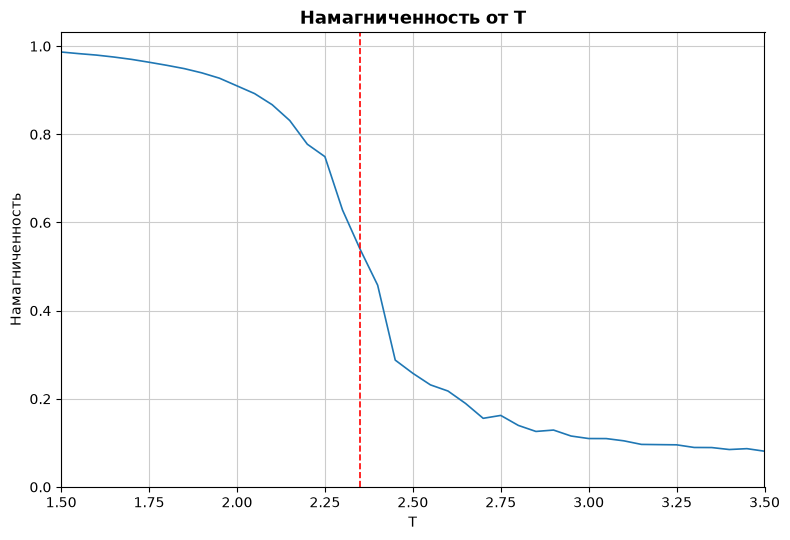

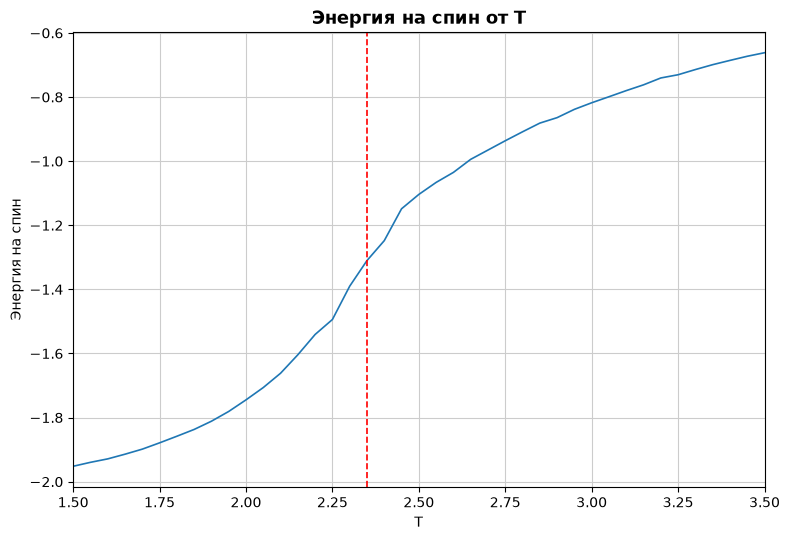

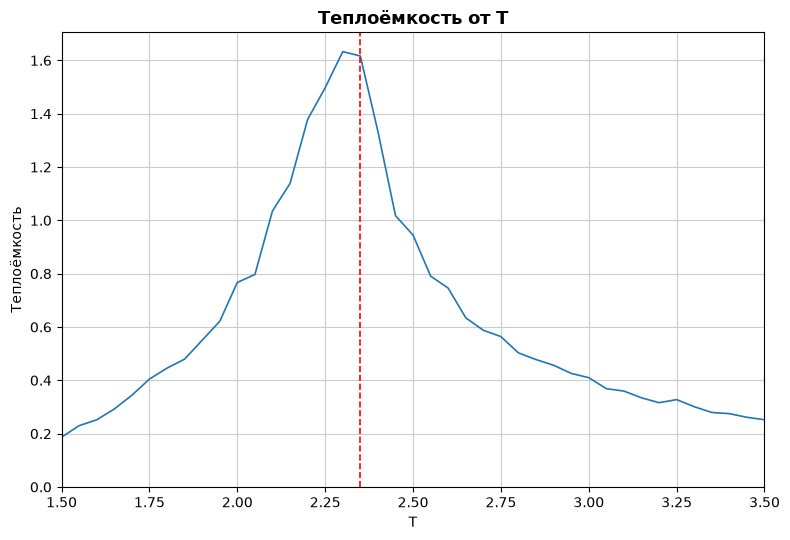

In [37]:
if RUN_LATTICE_CHECK:
  lat = lattice_network(24)
  res_lat = run_simulation(lat, np.linspace(1.5, 3.5, 41), n_thermal=1000, n_measure=2000, n_runs=3, seed=1)
  print(f"T_c по пику χ = {res_lat['Tc_chi']:.2f}, по пику C = {res_lat['Tc_C']:.2f} (точное значение 2.269)")
  plot_all(res_lat)

## 6. Загрузка сетей и их топология

[Denmark_highvoltage] загружено из ../data\Denmark_highvoltage.graphml: 63 узлов (в файле 96, компонент 2)
[Great-Britain_highvoltage] загружено из ../data\Great-Britain_highvoltage.graphml: 494 узлов (в файле 504, компонент 6)

                        Denmark_highvoltageGreat-Britain_highvoltage
N                                       63               494
рёбер                                   68               598
компонент (исходно)                      2                 6
<k>                                  2.159             2.421
<k^2>                                5.238             6.745
k_max                                    4                 7
кластеризация                        0.079             0.072
диаметр                                 27                55
T_c (Бете)                           1.150             1.580


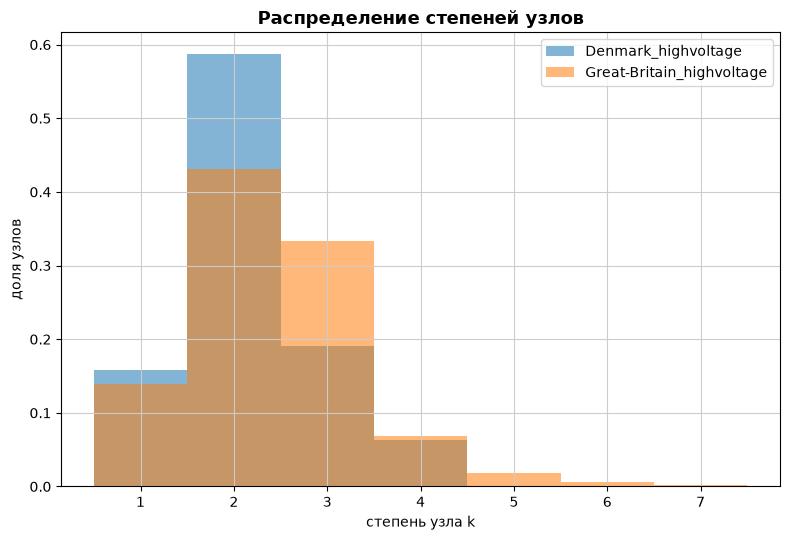

In [38]:
files = dict(GRAPH_FILES) if GRAPH_FILES else discover_graph_files(DATA_DIR)
if not files:
    raise FileNotFoundError(
        f"Не найдено ни одного графа. Положите файлы ({', '.join(GRAPH_EXTS)}) в папку "
        f"'{os.path.abspath(DATA_DIR)}' или заполните GRAPH_FILES.")

networks = {}
for label, path in files.items():
    try:
        G = read_graph_file(path)
        net = Network(label, G, use_largest=LARGEST_COMPONENT, use_weights=USE_WEIGHTS)
        if net.N < 2 or len(net.indices) == 0:
            raise ValueError("в графе нет рёбер")
        networks[label] = net
        print(f"[{label}] загружено из {path}: {net.N} узлов "
              f"(в файле {net.n_nodes_raw}, компонент {net.n_components_raw})")
    except Exception as exc:
        print(f"[{label}] ПРОПУЩЕН ({path}): {exc}")

if not networks:
    raise RuntimeError("Ни один граф не загрузился - см. сообщения выше.")

print()
print_topology(list(networks.values()))
plot_degree_distributions(list(networks.values()))

## 7. Термодинамика каждой сети

In [39]:
TEMPS = make_temps()
results = {}
for label, net in networks.items():
    results[label] = run_simulation(net, TEMPS, **SIM)

print()
print_summary(results)

[Denmark_highvoltage] запуск 1/5, 0.9 c
[Denmark_highvoltage] запуск 2/5, 2.1 c
[Denmark_highvoltage] запуск 3/5, 3.6 c
[Denmark_highvoltage] запуск 4/5, 4.5 c
[Denmark_highvoltage] запуск 5/5, 5.4 c
[Great-Britain_highvoltage] запуск 1/5, 7.6 c
[Great-Britain_highvoltage] запуск 2/5, 15.0 c
[Great-Britain_highvoltage] запуск 3/5, 22.6 c
[Great-Britain_highvoltage] запуск 4/5, 30.0 c
[Great-Britain_highvoltage] запуск 5/5, 37.3 c

сеть                        N    T_c (χ)    T_c (C)  T_c (ср.)     χ_max    C_max
Denmark_highvoltage        63      0.747      1.095      0.921       6.3    0.414
Great-Britain_highvoltage    494      1.025      1.025      1.025      18.4    0.586


===== Denmark_highvoltage (N = 63) =====


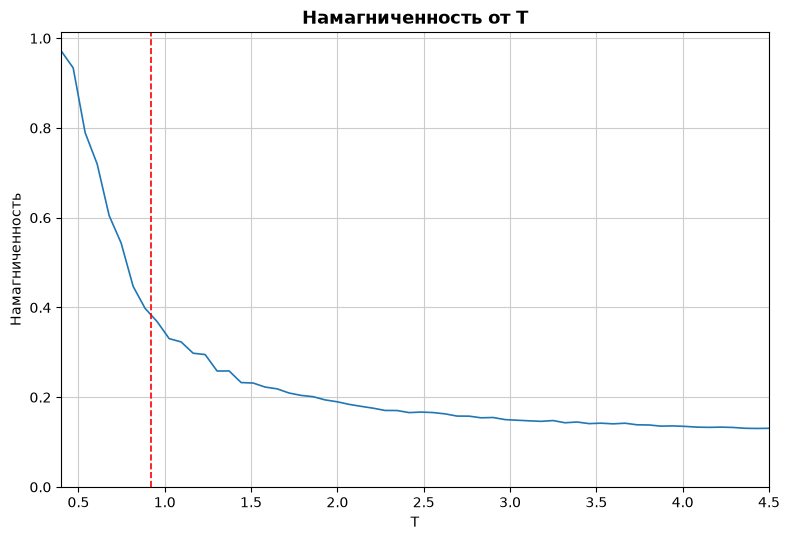

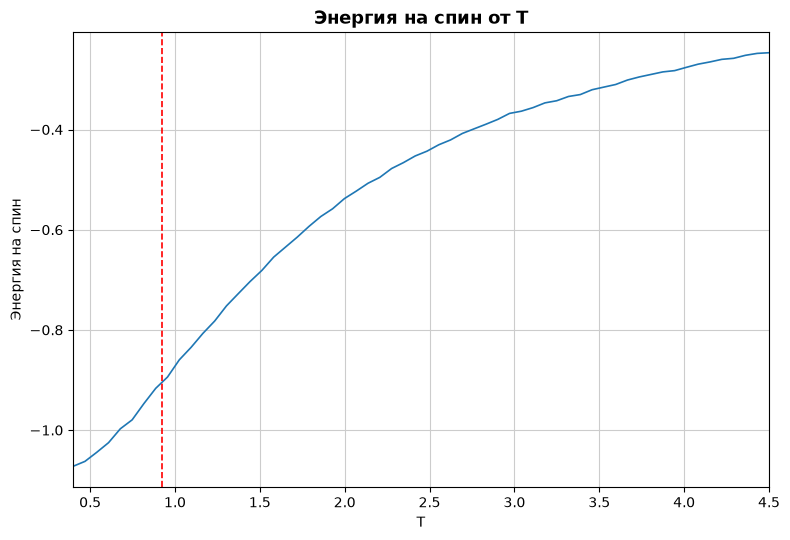

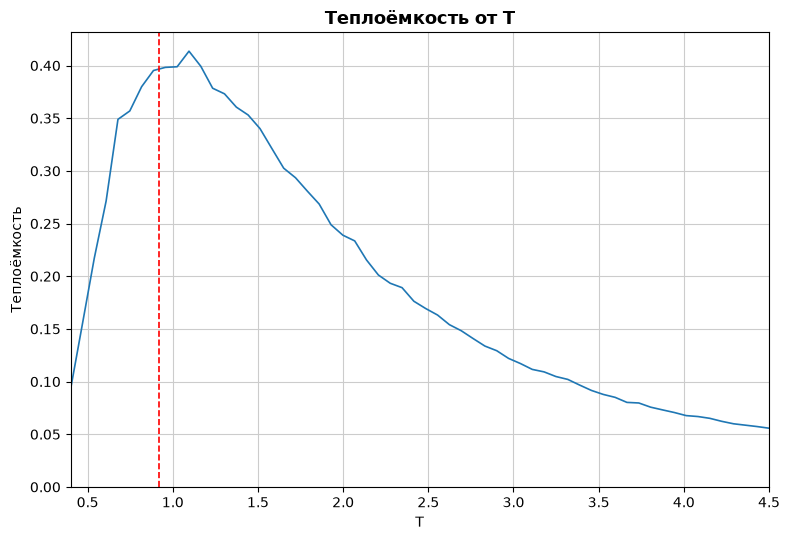

===== Great-Britain_highvoltage (N = 494) =====


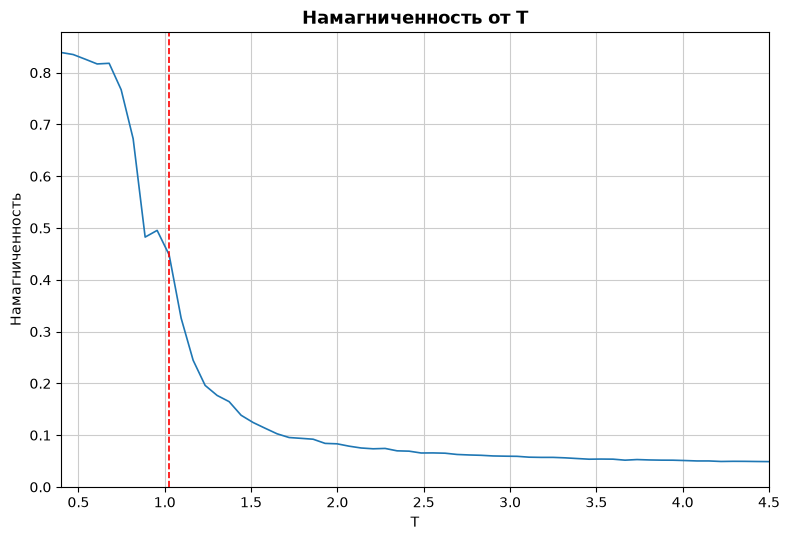

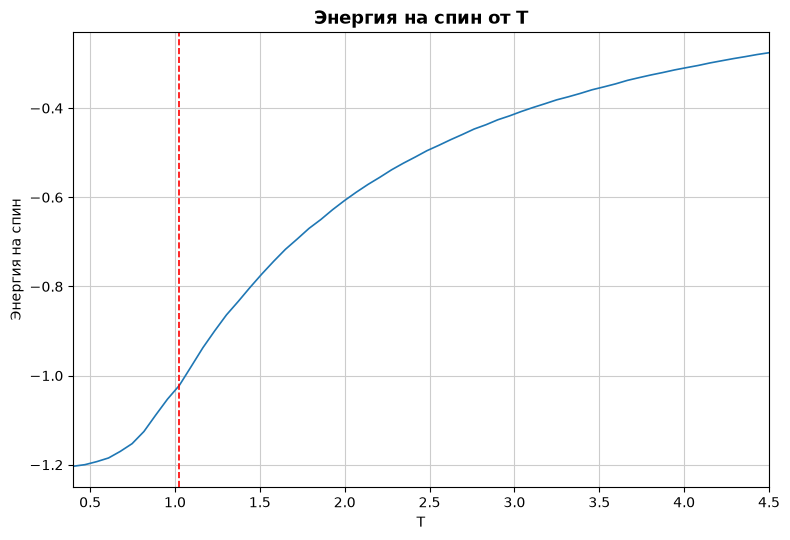

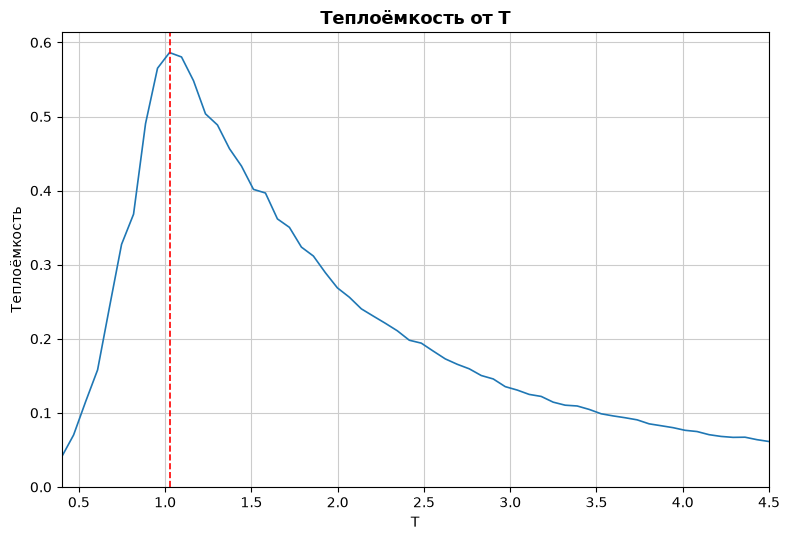

In [40]:
for label, res in results.items():
    print(f"===== {res['name']} (N = {res['N']}) =====")
    plot_all(res, show_std=False)

## 8. Сравнение сетей

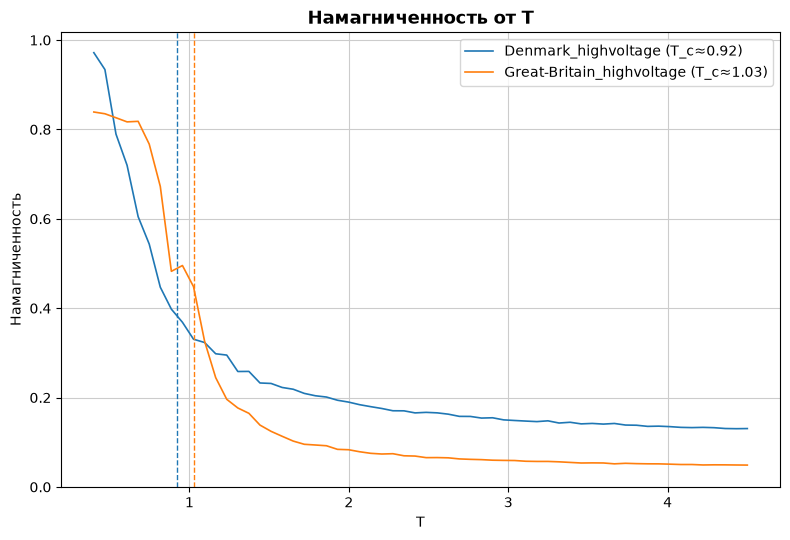

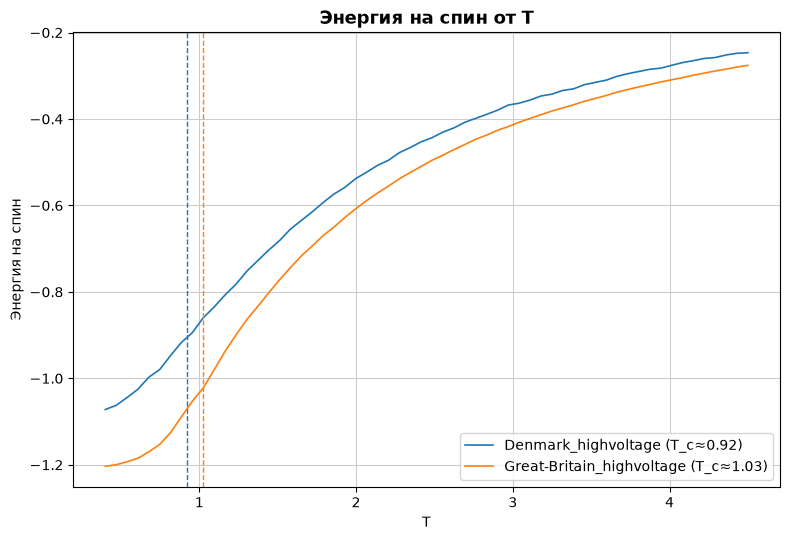

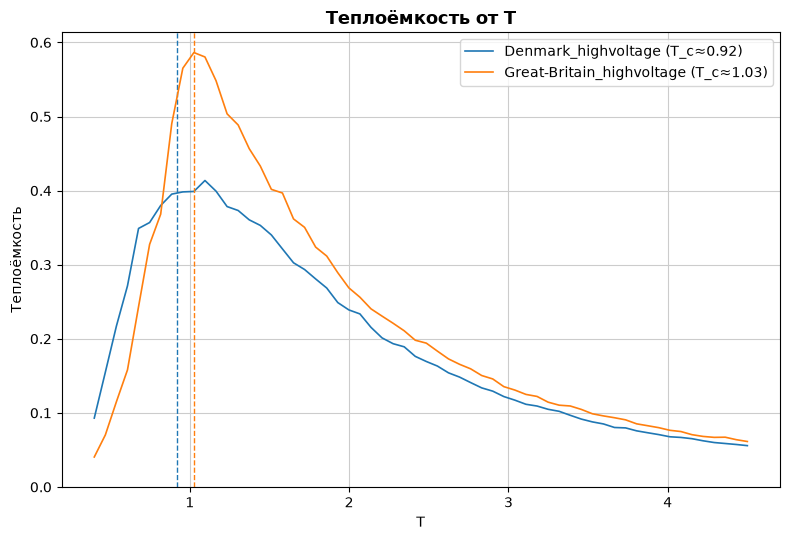

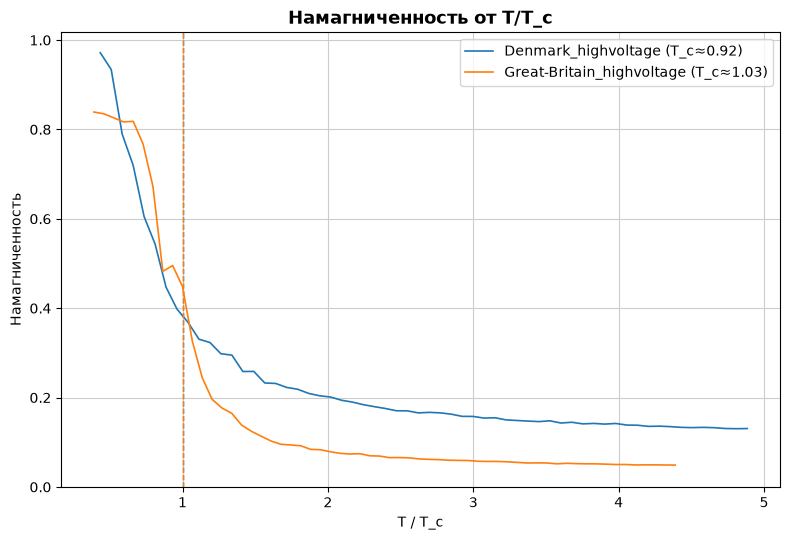

In [41]:
if len(results) > 1:
    plot_comparison(results, "m", "Намагниченность от T", "Намагниченность")
    plot_comparison(results, "e", "Энергия на спин от T", "Энергия на спин", zero_bottom=False)
    plot_comparison(results, "C", "Теплоёмкость от T", "Теплоёмкость")
    plot_comparison(results, "m", "Намагниченность от T/T_c", "Намагниченность", normalize=True)
else:
    print("Загружена только одна сеть - сравнивать не с чем.")

## 9. Состояние сети ниже, около и выше T_c

Синие узлы работают (`+1`), красные отказали (`-1`).

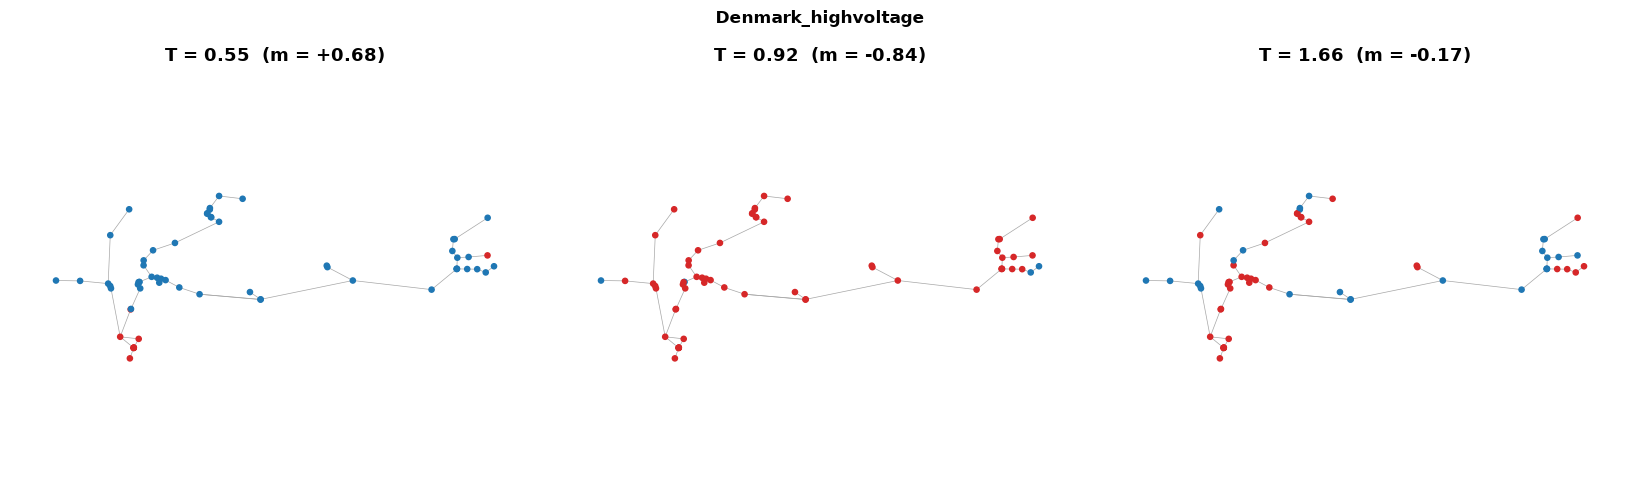

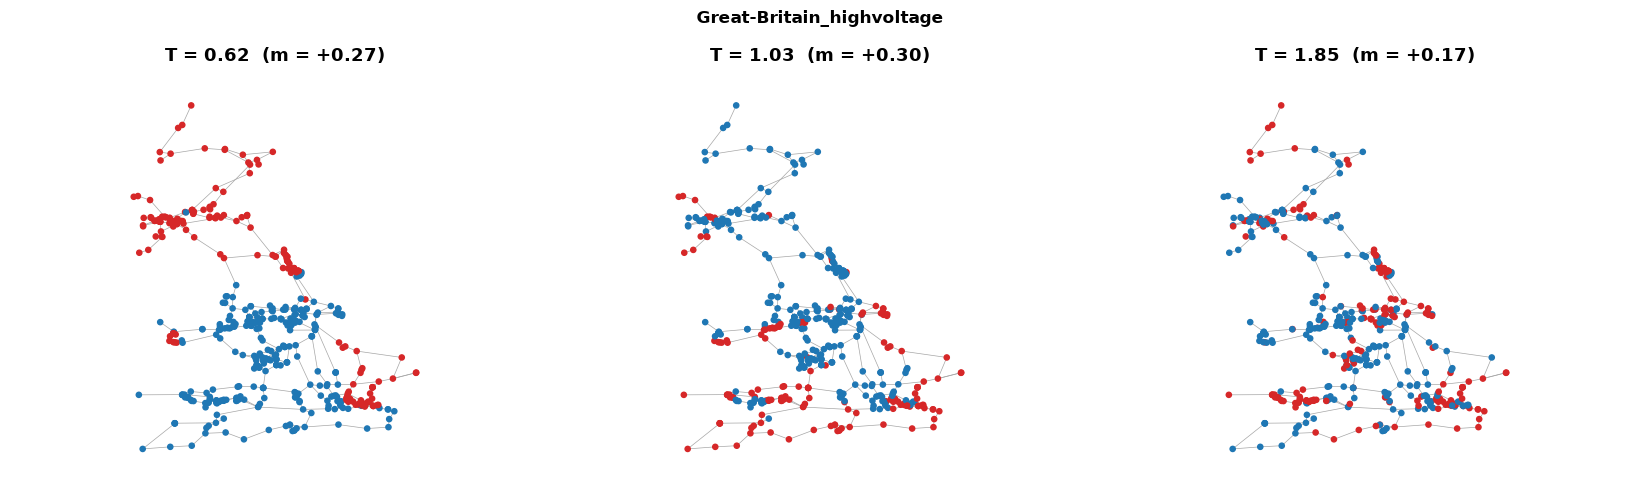

In [42]:
def get_positions(net):
    G = net.graph
    for kx, ky in (("x", "y"), ("lon", "lat"), ("longitude", "latitude"), ("Longitude", "Latitude")):
        try:
            return {v: (float(G.nodes[v][kx]), float(G.nodes[v][ky])) for v in net.nodes}
        except (KeyError, TypeError, ValueError):
            continue
    return nx.spring_layout(G, seed=1)


def sample_state(net, T, n_thermal=3000, seed=0):
    seed_numba(seed)
    spins = net.random_spins(np.random.default_rng(seed))
    relax(spins, net.indptr, net.indices, net.weights, J, 5.0, 300)
    relax(spins, net.indptr, net.indices, net.weights, J, float(T), n_thermal)
    return spins


def plot_states(net, tc, factors=(0.6, 1.0, 1.8)):
    pos = get_positions(net)
    xy = np.array([pos[v] for v in net.nodes])
    fig, axes = plt.subplots(1, len(factors), figsize=(5.5 * len(factors), 5))
    for ax, f in zip(np.atleast_1d(axes), factors):
        T = f * tc
        s = sample_state(net, T)
        nx.draw_networkx_edges(net.graph, pos, ax=ax, width=0.5, edge_color="0.65")
        ax.scatter(xy[:, 0], xy[:, 1], s=14, c=np.where(s > 0, "tab:blue", "tab:red"), zorder=3)
        ax.set_title(f"T = {T:.2f}  (m = {s.mean():+.2f})")
        ax.set_aspect("equal", adjustable="datalim")
        ax.axis("off")
    fig.suptitle(net.name, fontweight="bold")
    fig.tight_layout()
    plt.show()


for label, net in networks.items():
    plot_states(net, results[label]["Tc"])